# Compiled-circuit operator errors

Hardware-free comparison of each target gate $e^{-iV}$ with two order-$M$ operators, for
SM *Compiled-circuit errors* (the operator-error and relative-error tables and the pointwise
figure):

* **Fourier-truncated**: $e^{-iV}$ projected onto the $M+1$ centred harmonics, with the
  compiler's contractive rescale, the best approximation available at order $M$;
* **compiled**: $K_g(X)=\langle g|\hat U_M(X)|g\rangle$ rebuilt from the rotation angles run
  on hardware.

Every metric is evaluated over **each gate's own analysis window**, the window its analysis
notebook uses for the reported result, and over the full Fourier interval $|X|\le2$:

| gate | window | where it comes from |
|---|---|---|
| cubic | 1.8 | `01_cubic`: largest window at which Sim plus noise passes (median $p\ge0.10$) |
| symmetric / asymmetric / broken DW | 1.5 | topology window of `02`, `03`, `04` |
| Morse | 1.6 and 1.4 | `05_morse`: fit to the reconstruction (1.6) and to the measured points (1.4) |

**Input:** none; the targets and rotation angles are defined in the notebook.
**Output:** the pointwise figure `S4_operator_errors_pointwise.pdf` and `paper_values.json` in
`results_operator_errors/`; every quoted number is also printed between `PAPER VALUES` markers
for `extract_outputs.py`.

Figure size, tick intervals and line width are set in the **STYLE** block of the
configuration cell.

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ------------------------------------------------------------------ config
OUT = Path("results_operator_errors"); OUT.mkdir(exist_ok=True)

# ===================================================================== STYLE
# Everything about how the figure looks is set here and nowhere else.
# The background is always transparent and the axis labels are always kept.
# ---------------------------------------------------------------------------
CM = 1/2.54
def figsize_cm(w_cm, h_cm):
    return (w_cm*CM, h_cm*CM)

# whole-figure size in centimetres (width, height), including all panels
FIG_S4_CM = (7.0, 12.0)       # four panels stacked

LINEWIDTH = 1.0               # every data curve
AXIS_LW   = 0.8               # spines, ticks, reference lines
FONT_PT   = 8               # every label and tick label
FONT      = ["Calibri", "Carlito", "DejaVu Sans"]   # first one installed is used;
                            # Carlito is a metric-compatible stand-in for Calibri
SAVE_FORMATS = ("pdf",)     # add "svg" / "png" here if wanted

# tick interval in X, shared by every panel
X_MAJOR, X_MINOR = 1.0, 1.0

# tick intervals in Y, per panel: (major, minor).
# Set minor equal to (or larger than) major to suppress minor ticks entirely;
# set an entry to None to leave that axis to matplotlib.
Y_TICKS = {
    "acceptance": (0.2, 0.2),
    "fid_bound":  (0.1, 0.1),
    "dV":         (0.2, 0.2),
    "dF":         (2.0, 2.0),
}


def style_axes(ax, y_key=None, x_ticks=True):
    """Apply the tick intervals above. Minor ticks are drawn only when finer."""
    if x_ticks:
        ax.xaxis.set_major_locator(MultipleLocator(X_MAJOR))
        if X_MINOR and 0 < X_MINOR < X_MAJOR:
            ax.xaxis.set_minor_locator(MultipleLocator(X_MINOR))
    t = Y_TICKS.get(y_key)
    if t:
        maj, minr = t
        if maj:
            ax.yaxis.set_major_locator(MultipleLocator(maj))
        if minr and maj and 0 < minr < maj:
            ax.yaxis.set_minor_locator(MultipleLocator(minr))
    return ax

L          = 4.0
BETA       = 2*np.pi/L
W_FULL     = 2.0
XGRID      = np.linspace(-2.0, 2.0, 4001)
CONTRACTIVE_PEAK = 0.999
LEGENDRE_ORDER   = 1024

GATE_COLOR = {"cubic":"#6A3D9A", "symmetric DW":"#1B7837", "asymmetric DW":"#E66101",
              "broken DW":"#4575B4", "Morse":"#C51B7D"}
GATE_ORDER = ["cubic", "symmetric DW", "asymmetric DW", "broken DW", "Morse"]

# Analysis windows |X| <= W, one per reported result (see the table above).
# The first entry of each gate is its primary window, used in the summary tables.
WINDOWS = {"cubic":         [1.8],
           "symmetric DW":  [1.5],
           "asymmetric DW": [1.5],
           "broken DW":     [1.5],
           "Morse":         [1.6, 1.4]}
WIN_LABEL = lambda w: f"|X|<={w:.1f}"

# Shading in the pointwise figure: |X| beyond this lies outside every analysis
# window. Set to None for no shading.
SHADE_BEYOND = max(max(v) for v in WINDOWS.values())

GATE = "operator errors"          # label for the PAPER VALUES block
PAPER = {}

plt.rcParams.update({
    "font.size": FONT_PT, "axes.labelsize": FONT_PT,
    "xtick.labelsize": FONT_PT, "ytick.labelsize": FONT_PT,
    "font.family": "sans-serif", "font.sans-serif": FONT,
    # maths in the labels ($A_M(X)^2$, ...) in the same font
    "mathtext.fontset": "custom", "mathtext.rm": FONT[0],
    "mathtext.it": f"{FONT[0]}:italic", "mathtext.bf": f"{FONT[0]}:bold",
    "pdf.fonttype": 42,           # embed the font as TrueType, editable in Illustrator
    "axes.linewidth": AXIS_LW,
    "xtick.major.width": AXIS_LW, "ytick.major.width": AXIS_LW,
    "xtick.minor.width": AXIS_LW*0.75, "ytick.minor.width": AXIS_LW*0.75,
    "xtick.major.size": 3.0, "ytick.major.size": 3.0,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "figure.facecolor": "none", "axes.facecolor": "none",
    "savefig.transparent": True, "svg.fonttype": "none"})


from matplotlib import font_manager as _fm
_have = {f.name for f in _fm.fontManager.ttflist}
FONT_USED = next((f for f in FONT if f in _have), None)
print(f"font: {FONT_USED or 'none of ' + str(FONT) + ' found, matplotlib default'}")
if FONT_USED is None:
    plt.rcParams["mathtext.fontset"] = "dejavusans"
elif FONT_USED != FONT[0]:
    plt.rcParams.update({"mathtext.rm": FONT_USED, "mathtext.it": f"{FONT_USED}:italic",
                         "mathtext.bf": f"{FONT_USED}:bold"})


def save(fig, stem):
    """Transparent, in every format of SAVE_FORMATS (PDF for \\includegraphics)."""
    fig.tight_layout()
    for fmt in SAVE_FORMATS:
        fig.savefig(OUT/f"{stem}.{fmt}", format=fmt, transparent=True,
                    **({"dpi": 300} if fmt == "png" else {}))
        print(f"saved {OUT/f'{stem}.{fmt}'}")
    plt.show()

font: Calibri


## Programmed targets and rotation angles

The rotation angles are those run on hardware, as in the analysis notebooks. They were produced
by the compiler in `mathematica/phase_gate_angles.nb`, which also explains how an alternative
angle set relates to the Fourier-truncated operator below.

In [14]:
# ------------------------------------------------------------- targets
def _p(*c):
    """V(X) = sum_n c[n] X^(n+1), returned as (V, V')."""
    c = np.asarray(c, float)
    V  = lambda x: sum(c[n]*np.asarray(x, float)**(n+1) for n in range(len(c)))
    dV = lambda x: sum((n+1)*c[n]*np.asarray(x, float)**n for n in range(len(c)))
    return V, dV

_D, _a, _x0 = 0.6, 0.8, -0.5
_VM  = lambda x: _D*(1 - np.exp(-_a*(np.asarray(x, float) - _x0)))**2
_dVM = lambda x: 2*_D*_a*np.exp(-_a*(np.asarray(x, float) - _x0)) \
                 * (1 - np.exp(-_a*(np.asarray(x, float) - _x0)))

TARGETS = {
    "cubic":         _p(0.0,  0.0, 0.6, 0.0),
    "symmetric DW":  _p(0.0, -0.3, 0.0, 0.1),
    "asymmetric DW":     _p(0.1, -0.3, 0.0, 0.1),
    "broken DW": _p(0.6, -0.3, 0.0, 0.1),
    "Morse":         (_VM, _dVM),
}

# --------------------------------------------------- rotation angles (as run)
ROT_ASRUN = {
    "cubic": [
    (0.184405, 2.93141, 2.9065),
    (1.39646, 3.8613, 0.0),
    (1.44834, 6.09264, 0.0),
    (1.47146, 0.411717, 0.0),
    (1.11854, 5.85123, 0.0),
    (0.322625, 0.459188, 0.0),
    (1.33891, 2.42186, 0.0),
    (0.734034, 3.06676, 0.0),
    (1.24941, 0.119462, 0.0),
    (1.14211, 3.21129, 0.0),
    (0.688893, 0.101973, 0.0),
    (0.794593, 3.12217, 0.0),
],
    "asymmetric DW": [
    (0.336648, -0.269348, -1.45202),
    (1.13682, 2.53879, 0.0),
    (1.19228, 3.59511, 0.0),
    (1.3067, 3.14857, 0.0),
    (1.20813, 2.47598, 0.0),
    (1.0878, 6.26696, 0.0),
    (0.802639, 1.91157, 0.0),
    (0.177074, 5.08963, 0.0),
    (0.807996, 5.85005, 0.0),
    (1.04362, 2.47982, 0.0),
    (1.20526, 2.75286, 0.0),
    (1.21633, 3.47661, 0.0),
    (1.21826, 2.83425, 0.0),
    (1.09209, 6.01735, 0.0),
    (0.343483, 3.9368, 0.0),
],
    "broken DW": [
    (0.21898, 1.10606, 0.809167),
    (1.11214, 3.92899, 0.0),
    (1.06721, 3.43005, 0.0),
    (1.18029, 3.0126, 0.0),
    (1.29495, 2.88874, 0.0),
    (1.19385, 1.66121, 0.0),
    (0.819419, 0.662157, 0.0),
    (0.25738, 4.16433, 0.0),
    (0.831021, 1.55599, 0.0),
    (1.46442, 2.23498, 0.0),
    (1.34071, 2.94397, 0.0),
    (1.07443, 3.45289, 0.0),
    (0.930696, 0.443031, 0.0),
    (0.399867, 1.45762, 0.0),
],
    "symmetric DW": [
    (0.252632, 0.0302548, -2.11279),
    (1.26653, 3.12271, 0.0),
    (1.17213, 3.22627, 0.0),
    (1.08697, 3.11287, 0.0),
    (1.00808, 0.101898, 0.0),
    (0.936294, 1.5275, 0.0),
    (0.168949, 4.81704, 0.0),
    (0.928273, 5.99153, 0.0),
    (1.00288, 3.16116, 0.0),
    (1.09089, 2.97578, 0.0),
    (1.16624, 3.04565, 0.0),
    (1.24, 0.0498915, 0.0),
    (0.252994, 0.530284, 0.0),
],
    "Morse": [
    (0.415542, -0.0485164, -2.95614),
    (1.20521, 3.41858, 0.0),
    (1.22926, 3.93858, 0.0),
    (1.18716, 3.61958, 0.0),
    (1.03937, 3.72777, 0.0),
    (1.02387, 3.78534, 0.0),
    (0.926648, 0.0829967, 0.0),
    (0.228004, 2.63327, 0.0),
    (1.15102, 3.04471, 0.0),
    (1.29003, 3.37724, 0.0),
    (1.33179, 3.12756, 0.0),
    (1.2956, 2.87157, 0.0),
    (1.29862, 5.91143, 0.0),
    (0.173567, 3.4102, 0.0),
],
}

# These are the angles as run, extracted exactly as written in the Mathematica
# compiler (mathematica/phase_gate_angles.nb).  That notebook notes that writing
# the phase of the complementary polynomial with a factor of Pi gives an
# alternative angle set, whose circuit reproduces the Fourier-truncated operator
# below almost exactly; the as-run circuit is a different order-M unitary with
# operator errors of the same overall size.  Every result in the paper is
# compared with the circuit actually run, i.e. with these angles.

M_ORDER = {g: len(r) - 1 for g, r in ROT_ASRUN.items()}
print("circuit order M:", M_ORDER)
_miss = [g for g in GATE_ORDER if g not in ROT_ASRUN]
if _miss:
    raise ValueError(f"no rotation angles for {_miss}")

circuit order M: {'cubic': 11, 'asymmetric DW': 14, 'broken DW': 13, 'symmetric DW': 12, 'Morse': 13}


## Hardware-free operator engine and error budget

The order-$M$ truncation of $e^{-iV}$ with the compiler's contractive rescaling, and $K_g$
rebuilt from the rotation angles; both compared with the target after a global-phase
alignment on the window. The metrics are

* $\epsilon_A=1-A_M$ (amplitude), $\delta V=\arg(K_g e^{iV})$ (phase),
  $\delta V'=V_M'-V'$ (force), $\epsilon_K=|K_g-e^{-iV}|$ (operator);
* their r.m.s. and maxima over the window, and the fidelity bound
  $1-\mathcal F\lesssim(\max\epsilon_K)^2$;
* the phase error relative to $\Delta V=\max V-\min V$ and the force error relative
  to the r.m.s. of $V'$, both over the window;
* the acceptance $A_M^2$ (minimum, mean, and where the minimum sits).

In [15]:
def truncated_operator(Vfn, M, x, nq=LEGENDRE_ORDER):
    """Target truncated to the M+1 centred harmonics, with the contractive rescale."""
    h = np.arange(M+1, dtype=float) - M/2
    def coeffs(n):
        nd, wt = np.polynomial.legendre.leggauss(n)
        xq, wq = (L/2)*nd, (L/2)*wt
        Kq = np.exp(-1j*np.asarray(Vfn(xq), float))
        return np.array([np.sum(wq*Kq*np.exp(-1j*k*BETA*xq))/L for k in h], complex)
    c = 0.5*(coeffs(nq) + coeffs(2*nq))
    E = np.exp(1j*BETA*np.asarray(x, float)[:, None]*h[None, :])
    peak = float(np.max(np.abs(E@c)))
    cs = c*(min(1.0, CONTRACTIVE_PEAK/peak) if peak > 0 else 1.0)
    return E@cs, (E*(1j*BETA*h[None, :]))@cs


def compiled_operator(rots, x):
    """K_g and K_g' from the rotation angles, by the product rule."""
    RL = [np.array([[np.exp(1j*(l+p))*np.cos(t), np.exp(1j*p)*np.sin(t)],
                    [np.exp(1j*l)*np.sin(t), -np.cos(t)]], complex) for t, p, l in rots]
    def one(xv):
        S  = np.array([[0, np.exp(1j*BETA*xv/2)], [np.exp(-1j*BETA*xv/2), 0]], complex)
        Sp = np.array([[0, 1j*BETA/2*np.exp(1j*BETA*xv/2)],
                       [-1j*BETA/2*np.exp(-1j*BETA*xv/2), 0]], complex)
        U, Up = RL[0].copy(), np.zeros((2, 2), complex)
        for j in range(1, len(RL)):
            Up = RL[j]@(Sp@U + S@Up); U = RL[j]@S@U
        return U[0, 0], Up[0, 0]
    v = [one(float(t)) for t in x]
    return np.array([w[0] for w in v]), np.array([w[1] for w in v])


def error_curves(K, Kp, x, Vfn, dVfn, lim):
    """The four error curves on |x| <= lim, after global-phase alignment there."""
    w  = np.abs(x) <= lim
    xs = np.asarray(x, float)[w]
    Vt = np.asarray(Vfn(xs), float); Vt = Vt - np.interp(0.0, xs, Vt)
    Kt = np.exp(-1j*Vt)
    d  = np.angle(np.sum(np.conj(Kt)*K[w]))
    Ka, Kpa = K[w]*np.exp(-1j*d), Kp[w]*np.exp(-1j*d)
    F  = -np.imag(np.conj(Ka)*Kpa)/np.maximum(np.abs(Ka)**2, 1e-12)
    return xs, {"amplitude": np.abs(np.abs(Ka) - 1.0),
                "phase_rad": np.abs(np.angle(Ka*np.conj(Kt))),
                "force":     np.abs(F - np.asarray(dVfn(xs), float)),
                "operator":  np.abs(Ka - Kt)}


rms = lambda a: float(np.sqrt(np.mean(np.asarray(a)**2)))


def target_scales(Vfn, dVfn, lim):
    """Delta V = max V - min V and rms V' over |x| <= lim."""
    xs = XGRID[np.abs(XGRID) <= lim]
    V, dV = np.asarray(Vfn(xs), float), np.asarray(dVfn(xs), float)
    return float(V.max() - V.min()), rms(dV)


OPS, CURVES, BUDGET = {}, {}, []
for gate in GATE_ORDER:
    Vfn, dVfn = TARGETS[gate]
    OPS[(gate, "Fourier-truncated")] = truncated_operator(Vfn, M_ORDER[gate], XGRID)
    OPS[(gate, "compiled")]          = compiled_operator(ROT_ASRUN[gate], XGRID)
    lims = [(w, "analysis" if k == 0 else "analysis (alt)") for k, w in enumerate(WINDOWS[gate])]
    lims.append((W_FULL, "full"))
    for name in ("Fourier-truncated", "compiled"):
        K, Kp = OPS[(gate, name)]
        for lim, kind in lims:
            xs, m = error_curves(K, Kp, XGRID, Vfn, dVfn, lim)
            if kind == "full":
                CURVES[(gate, name)] = (xs, m)
            a  = np.abs(K[np.abs(XGRID) <= lim])**2
            dVr, dFr = target_scales(Vfn, dVfn, lim)
            BUDGET.append({"gate": gate, "M": M_ORDER[gate], "circuit": name,
                           "window": WIN_LABEL(lim), "lim": lim, "kind": kind,
                           **{f"{k}_rms": rms(v) for k, v in m.items()},
                           **{f"{k}_max": float(np.max(v)) for k, v in m.items()},
                           "fid_bound": float(np.max(m["operator"])**2),
                           "DeltaV": dVr, "Vp_rms": dFr,
                           "phase_rel": rms(m["phase_rad"])/dVr,
                           "force_rel": rms(m["force"])/dFr,
                           "acc_min": float(a.min()), "acc_mean": float(a.mean()),
                           "X_acc_min": float(xs[np.argmin(a)])})
BUDGET = pd.DataFrame(BUDGET)

COLS = ["M", "amplitude_rms", "phase_rad_rms", "force_rms", "operator_rms",
        "operator_max", "fid_bound"]
pd.set_option("display.width", 200)
for kind in ("analysis", "analysis (alt)", "full"):
    sel = BUDGET[BUDGET.kind == kind]
    print(f"\n=== operator budget, {kind} window ===")
    display(sel.set_index(["gate", "window", "circuit"])[COLS].round(4))


=== operator budget, analysis window ===


M  amplitude_rms  phase_rad_rms  force_rms  operator_rms  operator_max  fid_bound
gate          window   circuit                                                                                              
cubic         |X|<=1.8 Fourier-truncated  11         0.0420         0.0238     0.1623        0.0480        0.0833     0.0069
                       compiled           11         0.0167         0.0484     0.3257        0.0510        0.1017     0.0103
symmetric DW  |X|<=1.5 Fourier-truncated  12         0.0121         0.0083     0.0882        0.0146        0.0235     0.0006
                       compiled           12         0.0064         0.0132     0.0979        0.0146        0.0448     0.0020
asymmetric DW |X|<=1.5 Fourier-truncated  14         0.0217         0.0097     0.1154        0.0237        0.0383     0.0015
                       compiled           14         0.0124         0.0258     0.1306        0.0285        0.0570     0.0032
broken DW     |X|<=1.5 Fourier-truncated  13         0.0546         0.0127     0.1278        0.0560        0.0867     0.0075
                       compiled           13         0.0283         0.0281     0.2005        0.0394        0.1190     0.0142
Morse         |X|<=1.6 Fourier-truncated  13         0.0575         0.0230     0.2609        0.0617        0.0897     0.0080
                       compiled           13         0.0294         0.0715     0.2527        0.0761        0.1882     0.0354


=== operator budget, analysis (alt) window ===


M  amplitude_rms  phase_rad_rms  force_rms  operator_rms  operator_max  fid_bound
gate  window   circuit                                                                                              
Morse |X|<=1.4 Fourier-truncated  13         0.0577         0.0212     0.2369        0.0612        0.0829     0.0069
               compiled           13         0.0255         0.0588     0.2471        0.0634        0.1601     0.0256


=== operator budget, full window ===


M  amplitude_rms  phase_rad_rms  force_rms  operator_rms  operator_max  fid_bound
gate          window   circuit                                                                                              
cubic         |X|<=2.0 Fourier-truncated  11         0.0469         0.0259     0.2895        0.0533        0.1177     0.0139
                       compiled           11         0.0159         0.0493     0.4340        0.0516        0.1020     0.0104
symmetric DW  |X|<=2.0 Fourier-truncated  12         0.0126         0.0194     0.3500        0.0230        0.1240     0.0154
                       compiled           12         0.0146         0.0235     0.3535        0.0274        0.1275     0.0162
asymmetric DW |X|<=2.0 Fourier-truncated  14         0.0227         0.0361     0.5019        0.0421        0.3031     0.0919
                       compiled           14         0.0525         0.0484     0.5907        0.0700        0.3197     0.1022
broken DW     |X|<=2.0 Fourier-truncated  13         0.0586         0.0625     0.7486        0.0830        0.4687     0.2197
                       compiled           13         0.0411         0.0775     0.7284        0.0855        0.4089     0.1672
Morse         |X|<=2.0 Fourier-truncated  13         0.0653         0.0504     0.7104        0.0812        0.4093     0.1675
                       compiled           13         0.1402         0.1090     0.9022        0.1720        0.5704     0.3254

## The operators pointwise

$K_g(X)$ evaluated on a grid across the whole design interval $|X|\le2$; at each $X$
it is one complex number, so each panel is a single-valued function, and the
budget table entries are summaries of these curves over a window. Shading marks
$|X|>$ `SHADE_BEYOND` (1.8), outside every analysis window.

**(a) acceptance** $A_M(X)^2=|K_g(X)|^2$, the heralding probability. The target is
1; the contractive rescale keeps it below.

**(b)** $1-\epsilon_K(X)^2$, with $\epsilon_K=|K_a-e^{-iV}|$. The quoted fidelity
bound uses $\max\epsilon_K$ over the window, so it is set by the worst point of
this curve, at the window edge. $\epsilon_K$ folds together the amplitude deficit
of (a) and the phase error of (c).

**(c) phase error** $\delta V(X)=\arg(K_aK_{\rm tar}^*)$, signed: it oscillates about
zero at the first omitted harmonic.

**(d) force error** $\delta V'(X)=V_M'(X)-V'(X)$ with
$V_M'=-\mathrm{Im}[K_g^*K_g']/|K_g|^2$, the quantity the experiment measures.
Independent of the global phase.

$K_a=K_ge^{-i\delta}$ removes the unobservable global phase, with $\delta$ fitted over
`ALIGN_LIM` $=2$, which matches the full-interval rows of the budget. Curves are
the compiled (as-run) operators; set `FIG_CIRCUIT = "Fourier-truncated"` for the
truncated ones.

saved results_operator_errors\S4_operator_errors_pointwise.pdf


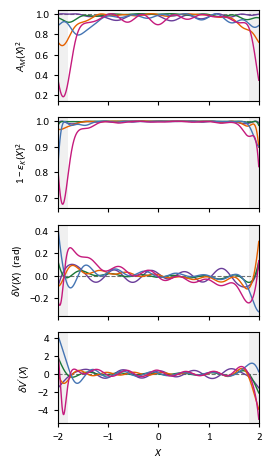


=== compiled: plotted curves vs budget (|X|<=2, aligned on |X|<=2.0) ===
gate               rms dV    max eK    budget    rms dV_p    budget
cubic             0.04929   0.10199   0.10199     0.43403   0.43403
symmetric DW      0.02346   0.12746   0.12746     0.35347   0.35347
asymmetric DW     0.04839   0.31972   0.31972     0.59066   0.59066
broken DW         0.07751   0.40894   0.40894     0.72837   0.72837
Morse             0.10900   0.57040   0.57040     0.90220   0.90220

=== where the errors grow (compiled) ===
gate               W  max eK |X|<=1  max eK |X|<=W   max eK  max|dV_p| |X|<=1   |X|<=W   |X|=2
cubic            1.8          0.061          0.102    0.102             0.475    0.597    1.56
symmetric DW     1.5          0.021          0.043    0.127             0.129    0.215    2.13
asymmetric DW    1.5          0.034          0.058    0.320             0.199    0.275    3.97
broken DW        1.5          0.063          0.128    0.409             0.337    0.513    4.25
M

In [16]:
ALIGN_LIM   = W_FULL        # matches the |X|<=2 rows of the budget
FIG_CIRCUIT = "compiled"    # or "Fourier-truncated"
FIG_STEM    = "S4_operator_errors_pointwise"

def pointwise(K, Kp, Vfn, dVfn, x, align_lim):
    """Acceptance, fidelity bound, phase error, force error. One value per x."""
    Vt    = np.asarray(Vfn(x), float); Vt = Vt - np.interp(0.0, x, Vt)
    Kt    = np.exp(-1j*Vt)
    m     = np.abs(x) <= align_lim
    d     = np.angle(np.sum(np.conj(Kt[m])*K[m]))      # unobservable global phase
    Ka    = K*np.exp(-1j*d)
    eK    = np.abs(Ka - Kt)
    # the force is a ratio in which the global phase cancels: no align_lim dependence
    F     = -np.imag(np.conj(K)*Kp)/np.maximum(np.abs(K)**2, 1e-12)
    return {"acceptance": np.abs(K)**2,
            "fid_bound":  1.0 - eK**2,
            "dV":         np.angle(Ka*np.conj(Kt)),
            "dF":         F - np.asarray(dVfn(x), float),
            "eK":         eK}


PANELS = [("acceptance", r"$A_M(X)^2$",            1.0),
          ("fid_bound",  r"$1-\epsilon_K(X)^2$",   1.0),
          ("dV",         r"$\delta V(X)$  (rad)",  0.0),
          ("dF",         r"$\delta V'(X)$",        0.0)]


def make_figure(circuit, stem):
    """The four-panel figure for one operator level. Returns its curves."""
    gates  = GATE_ORDER
    curves = {g: pointwise(*OPS[(g, circuit)], *TARGETS[g], XGRID, ALIGN_LIM)
              for g in gates}

    fig, axes = plt.subplots(4, 1, figsize=figsize_cm(*FIG_S4_CM), sharex=True)
    for ax, (key, lab, ref) in zip(axes, PANELS):
        for g in gates:
            ax.plot(XGRID, curves[g][key], lw=LINEWIDTH, color=GATE_COLOR[g], label=g)
        ax.axhline(ref, color="0.45", lw=AXIS_LW, ls="--", zorder=0)
        if SHADE_BEYOND:
            for lo, hi in ((-2.0, -SHADE_BEYOND), (SHADE_BEYOND, 2.0)):
                ax.axvspan(lo, hi, color="0.55", alpha=0.13, lw=0, zorder=0)
        ax.set_xlim(-2, 2); style_axes(ax, key)
        ax.set_ylabel(lab)
    axes[-1].set_xlabel("$X$")
    save(fig, stem)                 # no legend: gate colours are given in the caption
    return curves


FIG = make_figure(FIG_CIRCUIT, FIG_STEM)

# ---- the plotted curves are the budget: their summaries against BUDGET
print(f"\n=== {FIG_CIRCUIT}: plotted curves vs budget (|X|<=2, aligned on |X|<={ALIGN_LIM}) ===")
print(f"{'gate':15s} {'rms dV':>9s} {'max eK':>9s} {'budget':>9s}"
      f"   {'rms dV_p':>9s} {'budget':>9s}")
_lvl = FIG_CIRCUIT
for g in GATE_ORDER:
    c = FIG[g]
    b = BUDGET[(BUDGET.gate == g) & (BUDGET.circuit == _lvl) & (BUDGET.kind == "full")].iloc[0]
    print(f"{g:15s} {rms(np.abs(c['dV'])):9.5f} {c['eK'].max():9.5f} {b.operator_max:9.5f}"
          f"   {rms(c['dF']):9.5f} {b.force_rms:9.5f}")

# where the errors grow: interior (|X|<=1) against the analysis window and |X|=2
print("\n=== where the errors grow (" + FIG_CIRCUIT + ") ===")
print(f"{'gate':15s} {'W':>4s} {'max eK |X|<=1':>14s} {'max eK |X|<=W':>14s} {'max eK':>8s}"
      f" {'max|dV_p| |X|<=1':>17s} {'|X|<=W':>8s} {'|X|=2':>7s}")
for g in GATE_ORDER:
    c   = FIG[g]
    W   = WINDOWS[g][0]
    i1, iW = np.abs(XGRID) <= 1.0, np.abs(XGRID) <= W
    row = {"eK_max_X1": c["eK"][i1].max(), "eK_max_W": c["eK"][iW].max(),
           "eK_max_2": c["eK"].max(),
           "dVp_max_X1": np.abs(c["dF"][i1]).max(), "dVp_max_W": np.abs(c["dF"][iW]).max(),
           "dVp_edge": np.abs(c["dF"][[0, -1]]).max()}
    print(f"{g:15s} {W:4.1f} {row['eK_max_X1']:14.3f} {row['eK_max_W']:14.3f} {row['eK_max_2']:8.3f}"
          f" {row['dVp_max_X1']:17.3f} {row['dVp_max_W']:8.3f} {row['dVp_edge']:7.2f}")
    for k, v in row.items():
        PAPER[f"pointwise.{g}.{k}"] = float(v)

# Morse: the compiled operator along the steep wall (X < 0) and at the far side
print("\n=== Morse " + FIG_CIRCUIT + ", pointwise ===")
print(f"{'X':>6s} {'A_M^2':>7s} {'eK':>7s} {'dV':>7s} {'dV_p':>7s} {'V_p':>7s}")
for x0 in (-1.8, -1.7, -1.6, -1.5, -1.4, -1.0, 0.0, 1.0, 1.4, 1.8):
    j = int(np.argmin(np.abs(XGRID - x0))); c = FIG["Morse"]
    print(f"{x0:6.2f} {c['acceptance'][j]:7.3f} {c['eK'][j]:7.3f} {c['dV'][j]:7.3f}"
          f" {c['dF'][j]:7.3f} {float(TARGETS['Morse'][1](x0)):7.2f}")
    PAPER[f"pointwise.Morse.X{x0:+.1f}"] = {"acc": c["acceptance"][j], "eK": c["eK"][j],
                                             "dV": c["dV"][j], "dVp": c["dF"][j]}

## Tables for the supplement and the values to quote

The operator-error table (r.m.s. of each metric and $\max\epsilon_K$ over the primary
window), the relative-error table, the acceptance and the fidelity bound. The Morse window
of the fit to the measured points (1.4) is printed as an extra row. Every number also goes to
the `PAPER VALUES` block below.

In [17]:
def _rows(kind):
    return BUDGET[BUDGET.kind == kind].set_index(["gate", "window", "circuit"])

for kind, title in (("analysis", "primary analysis window"),
                    ("analysis (alt)", "Morse direct-fit window"),
                    ("full", "full interval |X|<=2")):
    t = _rows(kind)
    if not len(t):
        continue
    print(f"\n=== operator-error table -- {title} ===")
    display(t[["M", "amplitude_rms", "phase_rad_rms", "force_rms",
               "operator_rms", "operator_max"]].round(3))
    print(f"\n=== relative-error table -- {title} ===")
    rel = t[["DeltaV", "phase_rel", "Vp_rms", "force_rel"]].copy()
    rel["phase_rel"] = (100*rel.phase_rel).round(1).astype(str) + "%"
    rel["force_rel"] = (100*rel.force_rel).round(0).astype(int).astype(str) + "%"
    display(rel.round(2))
    print(f"\n=== acceptance and fidelity bound -- {title} ===")
    display(t[["acc_min", "acc_mean", "X_acc_min", "fid_bound"]].round(4))

# ---- summary lines
for kind in ("analysis", "full"):
    sel = BUDGET[BUDGET.kind == kind]
    print(f"\n[{kind}]")
    for circ in ("Fourier-truncated", "compiled"):
        s = sel[sel.circuit == circ]
        w = s.loc[s.fid_bound.idxmax()]
        a = s.loc[s.acc_min.idxmin()]
        print(f"  {circ:18s} largest fidelity bound {w.fid_bound:.2e} ({w.gate}, {w.window});"
              f"  next largest {s.fid_bound.nlargest(2).iloc[-1]:.2e};"
              f"  lowest acceptance {a.acc_min:.3f} ({a.gate}, X={a.X_acc_min:+.2f})")
    # which metrics the compiled operator does worse on, gate by gate
    piv = sel.pivot_table(index="gate", columns="circuit",
                          values=["amplitude_rms", "phase_rad_rms", "force_rms", "operator_rms"])
    worse = {m: [g for g in GATE_ORDER if piv.loc[g, (m, "compiled")] > piv.loc[g, (m, "Fourier-truncated")]]
             for m in ("amplitude_rms", "phase_rad_rms", "force_rms", "operator_rms")}
    print("  compiled > truncated for:", {k: len(v) for k, v in worse.items()}, worse)

# ---- PAPER values
_key = {"Fourier-truncated": "trunc", "compiled": "comp"}
_met = {"amplitude_rms": "epsA_rms", "phase_rad_rms": "dV_rms", "force_rms": "dVp_rms",
        "operator_rms": "eK_rms", "operator_max": "eK_max", "phase_rad_max": "dV_max",
        "force_max": "dVp_max", "fid_bound": "fid_bound", "acc_min": "acc_min",
        "acc_mean": "acc_mean", "X_acc_min": "X_acc_min",
        "phase_rel": "dV_rel", "force_rel": "dVp_rel"}
for _, r in BUDGET.iterrows():
    w = f"W{r.lim:.1f}"
    PAPER[f"{r.gate}.M"] = int(r.M)
    PAPER[f"{r.gate}.{w}.DeltaV"]  = r.DeltaV
    PAPER[f"{r.gate}.{w}.Vp_rms"]  = r.Vp_rms
    for col, k in _met.items():
        PAPER[f"{r.gate}.{w}.{_key[r.circuit]}.{k}"] = r[col]
for kind in ("analysis", "full"):
    for circ in ("Fourier-truncated", "compiled"):
        s = BUDGET[(BUDGET.kind == kind) & (BUDGET.circuit == circ)]
        PAPER[f"max_fid_bound.{kind}.{_key[circ]}"] = float(s.fid_bound.max())
        PAPER[f"max_fid_bound.{kind}.{_key[circ]}.excl_Morse"] = float(s[s.gate != "Morse"].fid_bound.max())


=== operator-error table -- primary analysis window ===


M  amplitude_rms  phase_rad_rms  force_rms  operator_rms  operator_max
gate          window   circuit                                                                                   
cubic         |X|<=1.8 Fourier-truncated  11          0.042          0.024      0.162         0.048         0.083
                       compiled           11          0.017          0.048      0.326         0.051         0.102
symmetric DW  |X|<=1.5 Fourier-truncated  12          0.012          0.008      0.088         0.015         0.023
                       compiled           12          0.006          0.013      0.098         0.015         0.045
asymmetric DW |X|<=1.5 Fourier-truncated  14          0.022          0.010      0.115         0.024         0.038
                       compiled           14          0.012          0.026      0.131         0.029         0.057
broken DW     |X|<=1.5 Fourier-truncated  13          0.055          0.013      0.128         0.056         0.087
                       compiled           13          0.028          0.028      0.200         0.039         0.119
Morse         |X|<=1.6 Fourier-truncated  13          0.058          0.023      0.261         0.062         0.090
                       compiled           13          0.029          0.072      0.253         0.076         0.188


=== relative-error table -- primary analysis window ===


DeltaV phase_rel  Vp_rms force_rel
gate          window   circuit                                              
cubic         |X|<=1.8 Fourier-truncated    6.99      0.3%    2.61        6%
                       compiled             6.99      0.7%    2.61       12%
symmetric DW  |X|<=1.5 Fourier-truncated    0.22      3.7%    0.21       42%
                       compiled             0.22      5.9%    0.21       46%
asymmetric DW |X|<=1.5 Fourier-truncated    0.36      2.7%    0.23       49%
                       compiled             0.36      7.2%    0.23       56%
broken DW     |X|<=1.5 Fourier-truncated    1.80      0.7%    0.64       20%
                       compiled             1.80      1.6%    0.64       32%
Morse         |X|<=1.6 Fourier-truncated    1.19      1.9%    0.85       31%
                       compiled             1.19      6.0%    0.85       30%


=== acceptance and fidelity bound -- primary analysis window ===


...


=== relative-error table -- full interval |X|<=2 ===


DeltaV phase_rel  Vp_rms force_rel
gate          window   circuit                                              
cubic         |X|<=2.0 Fourier-truncated    9.60      0.3%    3.22        9%
                       compiled             9.60      0.5%    3.22       13%
symmetric DW  |X|<=2.0 Fourier-truncated    0.62      3.1%    0.64       55%
                       compiled             0.62      3.8%    0.64       55%
asymmetric DW |X|<=2.0 Fourier-truncated    0.95      3.8%    0.65       78%
                       compiled             0.95      5.1%    0.65       91%
broken DW     |X|<=2.0 Fourier-truncated    2.67      2.3%    0.88       85%
                       compiled             2.67      2.9%    0.88       83%
Morse         |X|<=2.0 Fourier-truncated    3.23      1.6%    1.82       39%
                       compiled             3.23      3.4%    1.82       50%


=== acceptance and fidelity bound -- full interval |X|<=2 ===


acc_min  acc_mean  X_acc_min  fid_bound
gate          window   circuit                                                   
cubic         |X|<=2.0 Fourier-truncated   0.8417    0.9195     -2.000     0.0139
                       compiled            0.9306    0.9753      0.262     0.0104
symmetric DW  |X|<=2.0 Fourier-truncated   0.9581    0.9769      1.786     0.0154
                       compiled            0.9162    0.9804     -1.785     0.0162
asymmetric DW |X|<=2.0 Fourier-truncated   0.9115    0.9578     -1.920     0.0919
                       compiled            0.6880    0.9419     -1.918     0.1022
broken DW     |X|<=2.0 Fourier-truncated   0.7475    0.8953      1.954     0.2197
                       compiled            0.7918    0.9410     -1.595     0.1672
Morse         |X|<=2.0 Fourier-truncated   0.6809    0.8872     -1.903     0.1675
                       compiled            0.1878    0.8818     -1.898     0.3254


[analysis]
  Fourier-truncated  largest fidelity bound 8.05e-03 (Morse, |X|<=1.6);  next largest 7.52e-03;  lowest acceptance 0.835 (broken DW, X=+1.39)
  compiled           largest fidelity bound 3.54e-02 (Morse, |X|<=1.6);  next largest 1.42e-02;  lowest acceptance 0.812 (broken DW, X=-1.50)
  compiled > truncated for: {'amplitude_rms': 0, 'phase_rad_rms': 5, 'force_rms': 4, 'operator_rms': 4} {'amplitude_rms': [], 'phase_rad_rms': ['cubic', 'symmetric DW', 'asymmetric DW', 'broken DW', 'Morse'], 'force_rms': ['cubic', 'symmetric DW', 'asymmetric DW', 'broken DW'], 'operator_rms': ['cubic', 'symmetric DW', 'asymmetric DW', 'Morse']}

[full]
  Fourier-truncated  largest fidelity bound 2.20e-01 (broken DW, |X|<=2.0);  next largest 1.68e-01;  lowest acceptance 0.681 (Morse, X=-1.90)
  compiled           largest fidelity bound 3.25e-01 (Morse, |X|<=2.0);  next largest 1.67e-01;  lowest acceptance 0.188 (Morse, X=-1.90)
  compiled > truncated for: {'amplitude_rms': 3, 'phase_rad_rms': 5,

In [18]:
# =====================================================================
#  Print the collected values between fixed markers (read by
#  extract_outputs.py) and write them to OUT/paper_values.json.
# =====================================================================
def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if isinstance(v, (list, tuple, np.ndarray)):
        return [_plain(x) for x in list(np.asarray(v, dtype=object).ravel())] \
            if isinstance(v, np.ndarray) else [_plain(x) for x in v]
    if isinstance(v, (np.bool_, bool)):
        return bool(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return float(v)
    return v


def _fmt(v):
    v = _plain(v)
    if isinstance(v, bool):
        return str(v)
    if isinstance(v, int):
        return str(v)
    if isinstance(v, float):
        if not np.isfinite(v):
            return "nan"
        return f"{v:.4g}" if (v == 0 or 1e-3 <= abs(v) < 1e5) else f"{v:.3e}"
    if isinstance(v, list):
        return "[" + ", ".join(_fmt(x) for x in v) + "]"
    if isinstance(v, dict):
        return "{" + ", ".join(f"{k}: {_fmt(x)}" for k, x in v.items()) + "}"
    return str(v)


import json
print(f"===== PAPER VALUES: {GATE} =====")
for _k, _v in PAPER.items():
    print(f"{_k} = {_fmt(_v)}")
print(f"===== END PAPER VALUES: {GATE} =====")
(OUT / "paper_values.json").write_text(json.dumps(_plain(PAPER), indent=1, default=str))

===== PAPER VALUES: operator errors =====
pointwise.cubic.eK_max_X1 = 0.06078
pointwise.cubic.eK_max_W = 0.102
pointwise.cubic.eK_max_2 = 0.102
pointwise.cubic.dVp_max_X1 = 0.475
pointwise.cubic.dVp_max_W = 0.5969
pointwise.cubic.dVp_edge = 1.559
pointwise.symmetric DW.eK_max_X1 = 0.02064
pointwise.symmetric DW.eK_max_W = 0.04319
pointwise.symmetric DW.eK_max_2 = 0.1275
pointwise.symmetric DW.dVp_max_X1 = 0.1291
pointwise.symmetric DW.dVp_max_W = 0.2147
pointwise.symmetric DW.dVp_edge = 2.131
pointwise.asymmetric DW.eK_max_X1 = 0.03351
pointwise.asymmetric DW.eK_max_W = 0.05793
pointwise.asymmetric DW.eK_max_2 = 0.3197
pointwise.asymmetric DW.dVp_max_X1 = 0.1995
pointwise.asymmetric DW.dVp_max_W = 0.2752
pointwise.asymmetric DW.dVp_edge = 3.97
pointwise.broken DW.eK_max_X1 = 0.06277
pointwise.broken DW.eK_max_W = 0.1276
pointwise.broken DW.eK_max_2 = 0.4089
pointwise.broken DW.dVp_max_X1 = 0.3366
pointwise.broken DW.dVp_max_W = 0.5128
pointwise.broken DW.dVp_edge = 4.251
pointwise.Mors

19509